In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(f"../data/raw/train-test.csv")
df_ = df.copy() # for model prototyping

In [3]:
df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [4]:
df.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


looking at the data summary: weight seem to have negative min. how is that possible? how can weight be negative? the likely reason: when you look at the maximum of the weight it is exact amount with sign change, that means someone didn't do good job of entering the data correctly. it need to be handled.

it also indicate that posted rate has huge outliers since, 75% of dataset fall within 3330.75. it also required to be handled. of course, it could also mean, it is large for a reason i.e. long distance, premium cargo, etc.

In [5]:
negative_weight_count = (df['weight'] < 0).sum()
print(f"Number of negative weights: {negative_weight_count}")

Number of negative weights: 292


In [6]:
df[df['weight'] < 0]

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
68,TR-000069,Amarillo,Dayton,33.17137,-104.36789,39.87206,-85.62931,1334.2,Reefer,-36559.0,2025-01-01,0.96102,2.11777,2831.27
204,TR-000205,Fresno,Tucson,33.07921,-119.79528,30.92733,-113.23037,496.2,Dry Van,-26670.0,2025-01-02,0.96903,2.13155,1046.92
206,TR-000207,Columbia,Raleigh,34.63570,-83.28506,35.37376,-77.47605,411.3,Reefer,-20003.0,2025-01-02,0.94800,2.31682,959.15
225,TR-000226,Greensboro,Lubbock,35.98195,-82.78379,29.87534,-99.85456,1317.4,Reefer,-23981.0,2025-01-02,1.00820,2.13918,2836.00
376,TR-000377,Madison,Providence,41.70243,-89.85588,37.37287,-69.50000,1331.1,Dry Van,-41397.0,2025-01-03,0.94787,1.91867,2522.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47404,TR-047405,Baton Rouge,Memphis,30.50134,-92.65374,35.56802,-89.52871,468.7,Dry Van,-24142.0,2025-10-28,0.94219,1.83201,1077.64
47431,TR-047432,Phoenix,Chattanooga,28.75668,-115.87725,35.29792,-87.18651,1978.6,Flatbed,-35617.0,2025-10-28,0.92870,2.00708,4295.45
47735,TR-047736,Houston,Reno,30.71157,-94.76550,39.54838,-118.64843,1689.1,Reefer,-43951.0,2025-10-30,1.04615,1.85824,3933.12
47850,TR-047851,Shreveport,Cincinnati,32.54628,-92.31888,37.15706,-86.77499,538.3,Dry Van,-28144.0,2025-10-31,0.98093,1.86958,1191.61


In [7]:
# one way to handle negative weight would be:
df['weight'] = df['weight'].abs()

In [8]:
df.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

there seem to be some NaN in weight and market_index features. they can either be dropped or imputed. in this case, i am choosing to impute.

but since the dataset is large, it is possible to drop them too.

In [9]:
df[df['weight'].isnull() | df['market_index'].isnull()]

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
116,TR-000117,Memphis,Fort Wayne,35.56802,-89.52871,41.31561,-85.36206,533.8,Reefer,30570.0,2025-01-01,NaN,2.37177,1271.10
226,TR-000227,Tampa,Hartford,28.35765,-86.94782,39.55328,-72.18051,1342.7,Reefer,26397.0,2025-01-02,NaN,2.01837,2743.13
311,TR-000312,Los Angeles,New York,28.56624,-116.70249,40.00674,-73.79840,2935.7,Flatbed,32807.0,2025-01-02,NaN,1.91236,5568.57
323,TR-000324,Richmond,San Francisco,38.09122,-76.78906,35.19670,-121.69849,2848.8,Reefer,NaN,2025-01-03,0.91370,1.92679,5430.07
511,TR-000512,Grand Rapids,Amarillo,43.43800,-86.29173,33.17137,-104.36789,1420.7,Reefer,19360.0,2025-01-04,NaN,1.94596,2786.63
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47582,TR-047583,Reno,Milwaukee,39.54838,-118.64843,39.62180,-88.48008,1852.6,Flatbed,NaN,2025-10-29,0.98255,2.10315,3789.30
47612,TR-047613,Dallas,Tulsa,31.83025,-94.38343,33.45894,-94.78556,144.8,Dry Van,22516.0,2025-10-29,NaN,1.41826,403.88
47700,TR-047701,Kansas City,Shreveport,39.41104,-91.12450,32.54628,-92.31888,570.8,Dry Van,NaN,2025-10-30,1.02462,1.98408,1262.99
47808,TR-047809,Cincinnati,Baltimore,37.15706,-86.77499,38.16908,-72.74564,908.7,Dry Van,NaN,2025-10-30,1.03320,2.18658,1819.36


In [10]:
# impute the missing values
# bit more advance way of handling missing weight,
# impute weight based on the equipment type
df['weight'] = df['weight'].fillna(df.groupby('equipment')['weight'].transform('median'))
df['market_index'] = df['market_index'].fillna(df['market_index'].median())

In [11]:
df.isnull().sum()

load_id         0
pickup          0
delivery        0
pickup_lat      0
pickup_lon      0
delivery_lat    0
delivery_lon    0
distance        0
equipment       0
weight          0
date            0
market_index    0
quote_signal    0
posted_rate     0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

now for the posted_rate

In [13]:
high_rates = df[df['posted_rate'] > 10000]
print(f"Number of rows with a rate over 10,000: {len(high_rates)}")

Number of rows with a rate over 10,000: 103


In [14]:
med_rates = df[df['posted_rate'] > 5000]
print(f"Number of rows with a rate over 5000: {len(med_rates)}")

Number of rows with a rate over 5000: 2265


In [15]:
print("\nTop 5 highest rates:")
print(high_rates['posted_rate'].nlargest(5))


Top 5 highest rates:
12184    25533.00
37764    24294.98
1466     24140.21
17371    23662.71
26235    23580.42
Name: posted_rate, dtype: float64


In [16]:
# Check which equipment type is pulling the highest rates
print(df.groupby('equipment')[['posted_rate', 'distance']].agg(['max', 'mean']))

          posted_rate              distance             
                  max         mean      max         mean
equipment                                               
Dry Van      25533.00  2271.548686   3396.6  1137.278718
Flatbed      17893.17  2445.087223   3360.1  1132.514715
Reefer       24140.21  2553.636939   3439.8  1135.073674


those additional info seem to suggest that they (posted_rate) are high for a reason, so they cannot be dropped rather we probably can use scaler to scale the dataset for LR, neural network, or model that requires scaled dataset.

In [17]:
# for now lets not drop the posted rate rather add another feature named:
df['log_posted_rate'] = np.log1p(df['posted_rate'])

In [18]:
df.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate,log_posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31417.711802,1.083172,2.062468,2373.980682,7.573160
std,4.315285,13.482431,4.317199,13.476589,728.564416,7971.490037,0.167452,0.291391,1486.493245,0.666531
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,5000.000000,0.676390,0.692280,57.220000,4.064229
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25961.000000,0.950610,1.891030,1251.555000,7.132941
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31486.500000,1.055800,2.055750,2030.760000,7.616658
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.218525,2.221685,3330.750000,8.111253
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000,10.147766


Feature engineering (creating new features)

In [19]:
# The Haversine formula calculates the great-circle distance between two points
# on the surface of a sphere given their longitudes and latitudes.
# It serves as an approximation of the true displacement (shortest distance)
# between two geographic locations on Earth, accounting for the planet's spherical curvature
# rather than assuming a flat map.
def calculate_haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 3956 * c

df['haversine_distance'] = calculate_haversine(df['pickup_lat'], df['pickup_lon'], df['delivery_lat'], df['delivery_lon'])
df['route_circuity'] = df['distance'] / (df['haversine_distance'] + 1e-5)

# midpoint of pickup and delivery
df['midpoint_lat'] = (df['pickup_lat'] + df['delivery_lat']) / 2
df['midpoint_lon'] = (df['pickup_lon'] + df['delivery_lon']) / 2

In [20]:
df['date'] = pd.to_datetime(df['date'])

df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
df['quarter'] = df['date'].dt.quarter

In [21]:
df['weight_per_mile'] = df['weight'] / df['distance']

In [22]:
weight_bins = [0, 20000, 42000, float('inf')]
weight_labels = ['light_Load', 'standard_load', 'heavy_max_load']
df['weight_class'] = pd.cut(df['weight'], bins=weight_bins, labels=weight_labels)

In [23]:
df['market_tension_index'] = df['market_index'] * df['quote_signal']

In [24]:
df['lane'] = df['pickup'].astype(str) + "_" + df['delivery'].astype(str)

In [25]:
df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,...,midpoint_lat,midpoint_lon,day_of_week,month,is_weekend,quarter,weight_per_mile,weight_class,market_tension_index,lane
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,...,38.130150,-74.767350,2,1,0,1,111.768137,standard_load,2.292541,Richmond_Baltimore
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,...,38.657195,-74.878080,2,1,0,1,62.584670,light_Load,2.375705,Richmond_Philadelphia
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,...,41.763065,-80.247905,2,1,0,1,32.776400,standard_load,1.862824,Philadelphia_Green Bay
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,...,37.201305,-79.234955,2,1,0,1,33.491817,standard_load,1.774216,Hartford_Atlanta
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,...,33.562520,-91.236290,2,1,0,1,64.925263,standard_load,2.524042,Dallas_Nashville


PLOTS

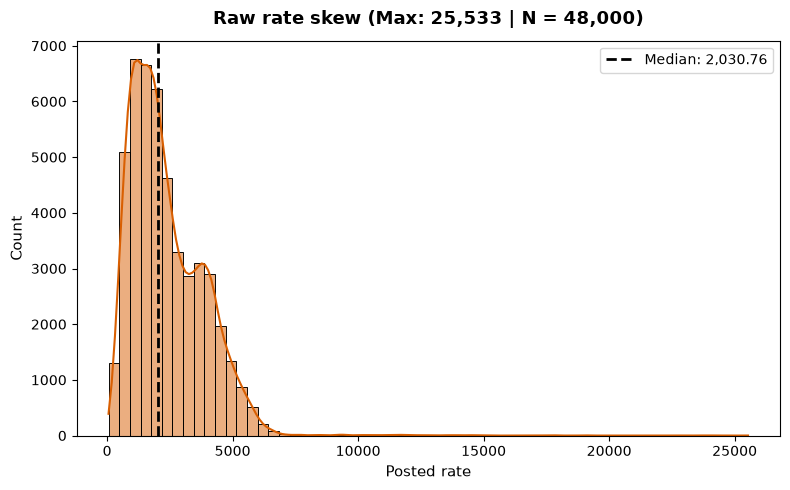

In [26]:
plt.figure(figsize=(8, 5))
sns.histplot(df["posted_rate"], kde=True, color="#d95f02", bins=60)

plt.axvline(2030.76, color="black", linestyle="--", linewidth=2, label="Median: 2,030.76")
plt.title("Raw rate skew (Max: 25,533 | N = 48,000)", fontsize=13, weight="bold", pad=12)
plt.xlabel("Posted rate", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.legend()

plt.tight_layout()
plt.show()

the plots shows that dataset is highly skewed by the outliers. though they may be due to having more expensive rate for some cargo/distance.

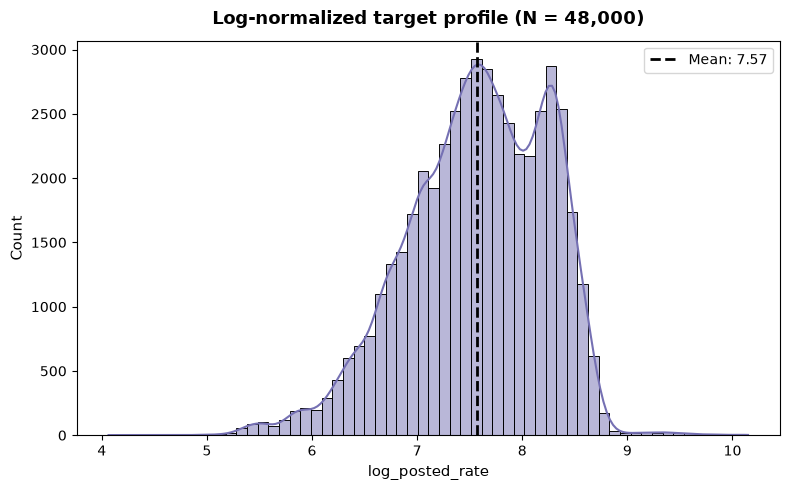

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(df["log_posted_rate"], kde=True, color="#7570b3", bins=60)

plt.axvline(7.57, color="black", linestyle="--", linewidth=2, label="Mean: 7.57")
plt.title("Log-normalized target profile (N = 48,000)", fontsize=13, weight="bold", pad=12)
plt.xlabel("log_posted_rate", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.legend()

plt.tight_layout()
plt.show()

yeah, this plot makes it pretty clear that there are two distinct rate (bimodal distribution) - normal and premium. let's dive deeper into it:

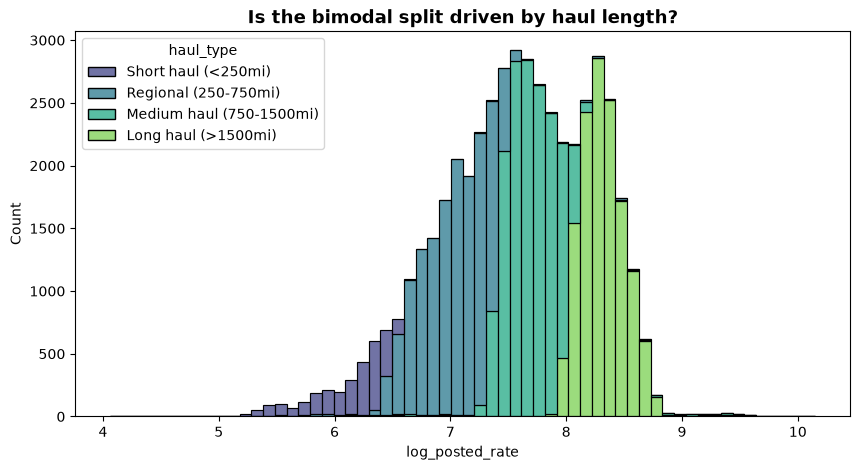

In [28]:
bins = [0, 250, 750, 1500, float("inf")]
labels = ["Short haul (<250mi)", "Regional (250-750mi)", "Medium haul (750-1500mi)", "Long haul (>1500mi)"]
df["haul_type"] = pd.cut(df["distance"], bins=bins, labels=labels)

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='log_posted_rate', hue='haul_type', multiple='stack', bins=60, palette='viridis')
plt.title("Is the bimodal split driven by haul length?", fontsize=13, weight='bold')
plt.xlabel("log_posted_rate")
plt.show()

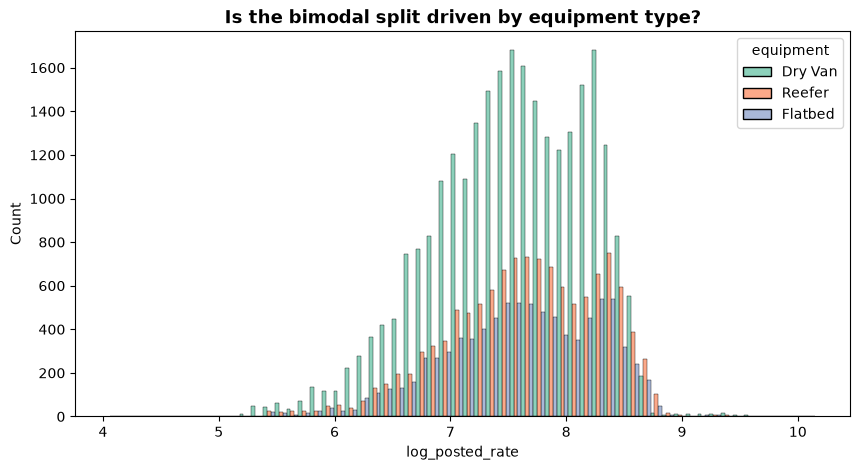

In [29]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='log_posted_rate', hue='equipment', multiple='dodge', bins=60, palette='Set2')
plt.title("Is the bimodal split driven by equipment type?", fontsize=13, weight='bold')
plt.xlabel("log_posted_rate")
plt.show()

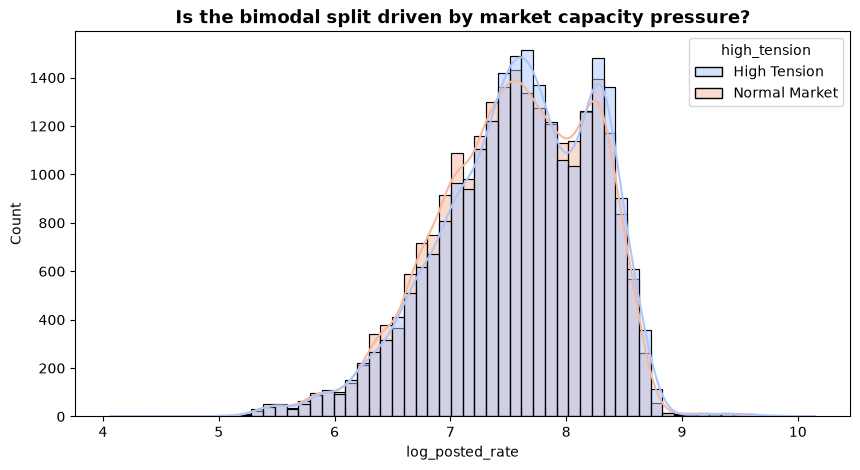

In [30]:
df['high_tension'] = (df['market_tension_index'] > df['market_tension_index'].median()).map({True: 'High Tension', False: 'Normal Market'})

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='log_posted_rate', hue='high_tension', kde=True, bins=60, palette='coolwarm')
plt.title("Is the bimodal split driven by market capacity pressure?", fontsize=13, weight='bold')
plt.xlabel("log_posted_rate")
plt.show()

<h3>bi-modal rate reasons</h3>

looking at those three plots, the main reason seem to be haul_type (how far to transport the packages).

look at the long haul (above 1500 miles range), it seems to be reason for bi-modal rate which makes sense, longer the range higher will be the cost.

looking at rate and equipment type & rate and market tension: there doesn't seem to be clear indication as to why bi-modal rate. they both seem to have two twin peak indicating they didn't cause the bi-modal rate.

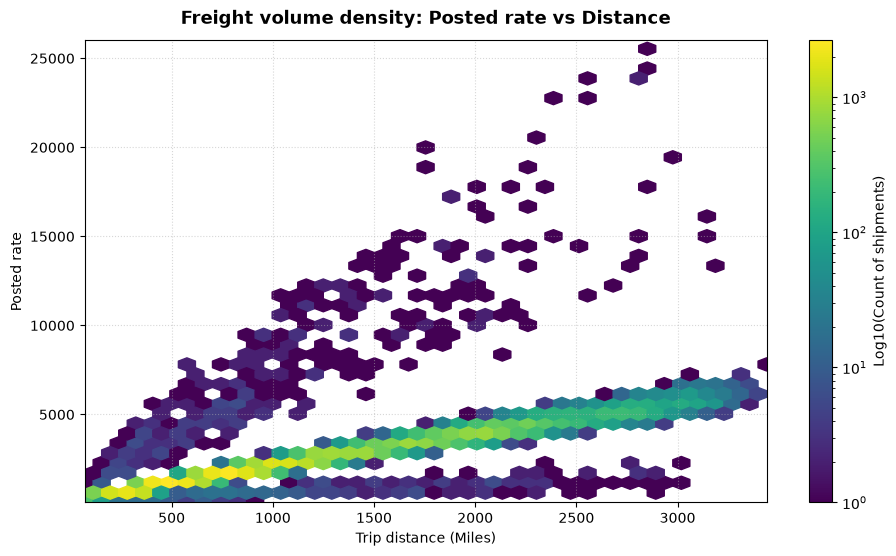

In [31]:
plt.figure(figsize=(11, 6))

hb = plt.hexbin(
    df['distance'], 
    df['posted_rate'], 
    gridsize=40, 
    cmap='viridis', 
    mincnt=1,
    bins='log'
)

cb = plt.colorbar(hb, label='Log10(Count of shipments)')
plt.title("Freight volume density: Posted rate vs Distance", fontsize=13, weight="bold", pad=12)
plt.xlabel("Trip distance (Miles)")
plt.ylabel("Posted rate")
plt.xlim(70, 3440)
plt.ylim(57, 26000)
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()


this chart shows a dense green stripe tracking linearly up to around 7,000, while a completely separate, sparse scattering of hexagons shoots up to 25,000. it confirms that distance is responsible for base rate, but a secondary mechanism triggers the premium pricing.

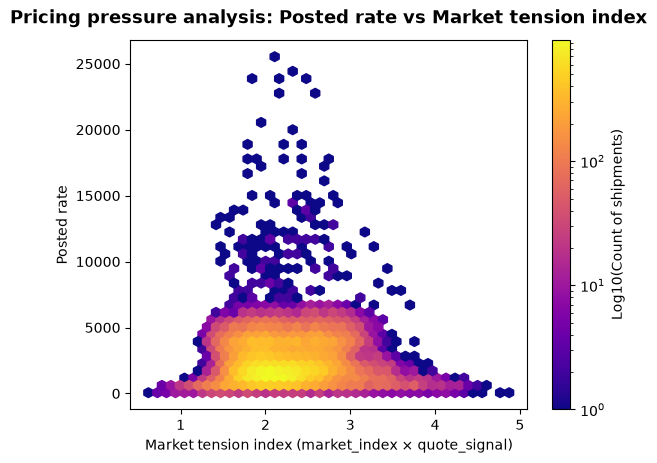

In [32]:
hb = plt.hexbin(
    df['market_tension_index'], 
    df['posted_rate'], 
    gridsize=40, 
    cmap='plasma', 
    mincnt=1,
    bins='log'
)

cb = plt.colorbar(hb, label='Log10(Count of shipments)')
plt.title("Pricing pressure analysis: Posted rate vs Market tension index", fontsize=13, weight="bold", pad=12)
plt.xlabel("Market tension index (market_index × quote_signal)")
plt.ylabel("Posted rate")
plt.show()

look at how tightly clustered the bulk of the shipments remain around index scores of 2.0 to 3.0. the extreme vertical outliers scaling past 15,000 appear almost exclusively inside this specific pressure zone rather than spreading randomly, meaning high prices are concentrated during high quote-to-market traffic spikes.

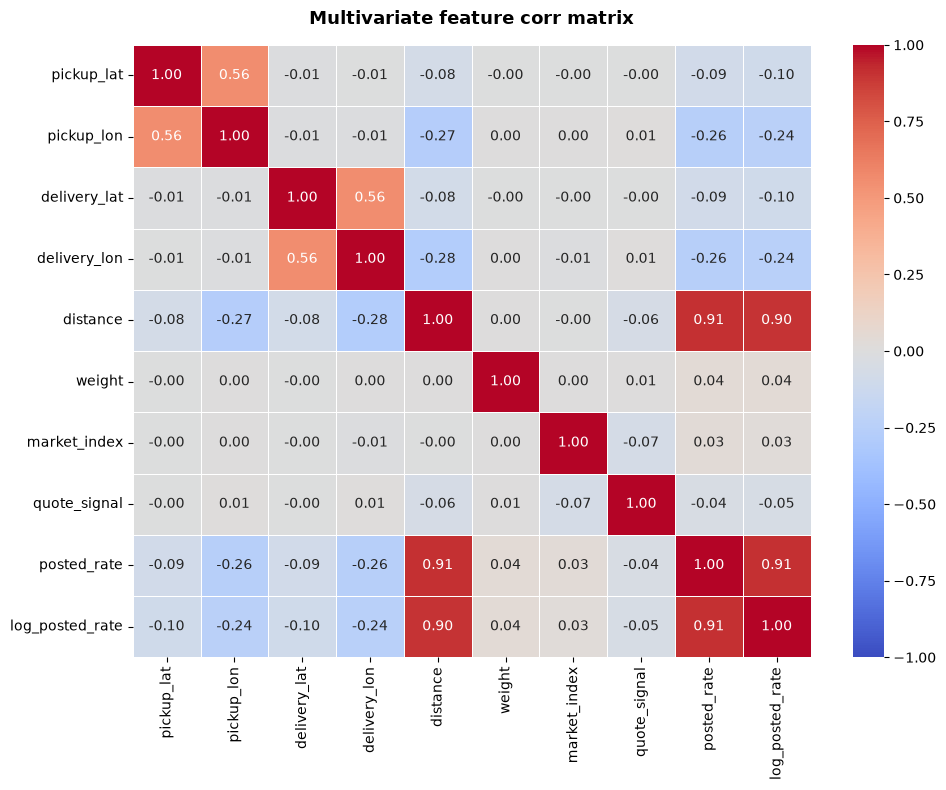

In [33]:
features = ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 
            'distance', 'weight', 'market_index', 'quote_signal', 'posted_rate', 'log_posted_rate']

plt.figure(figsize=(10, 8))
sns.heatmap(
    df[features].corr(), 
    annot=True, 
    cmap="coolwarm", 
    fmt=".2f", 
    linewidths=0.7, 
    vmin=-1, 
    vmax=1
)

plt.title("Multivariate feature corr matrix", fontsize=13, weight="bold", pad=15)
plt.tight_layout()
plt.show()

distance seem to have over 0.9 corr with posted_rate. where as weight and market_index seem to little to none corr with posted_rate. i will use non-linear model to handle those corr.

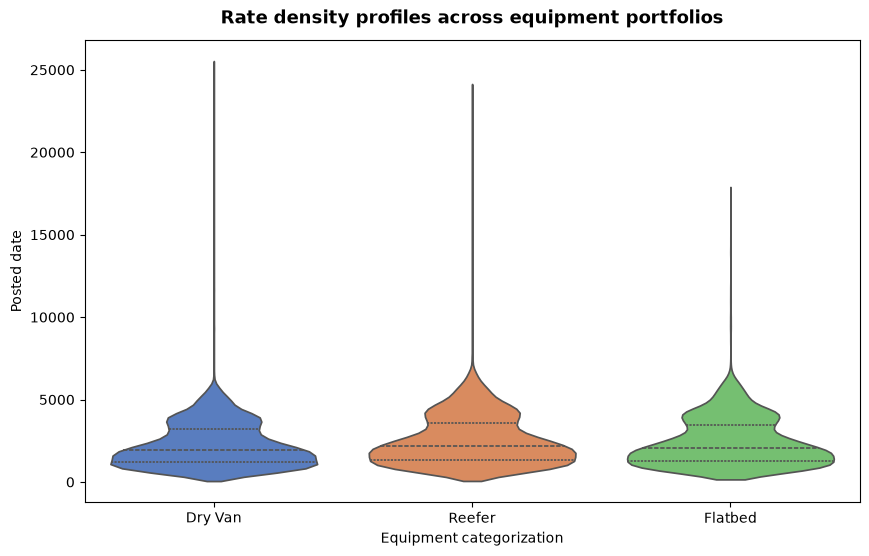

In [34]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df, 
    x='equipment', 
    y='posted_rate', 
    hue='equipment',
    palette='muted',
    legend=False, 
    inner='quart',
    cut=0
)

plt.title("Rate density profiles across equipment portfolios", fontsize=13, weight="bold", pad=12)
plt.xlabel("Equipment categorization")
plt.ylabel("Posted date")
plt.show()

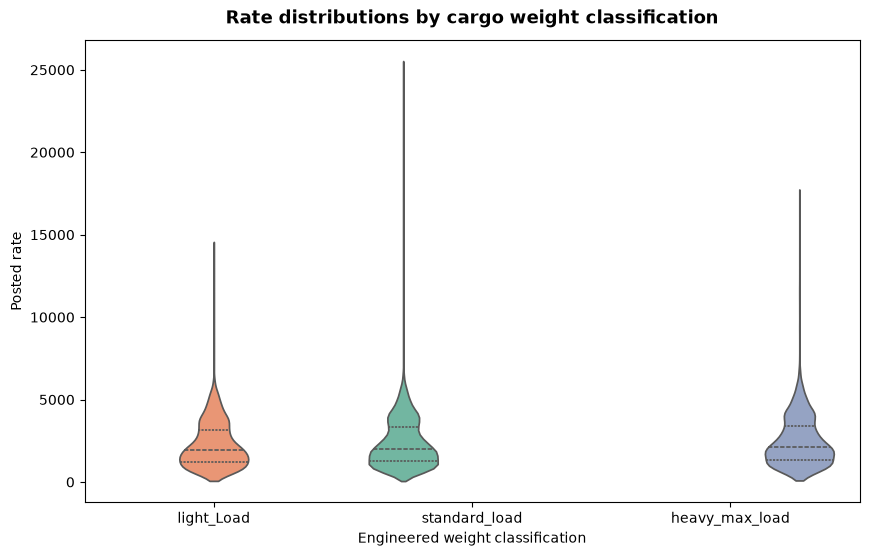

In [35]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='weight_class',
    y='posted_rate',
    hue='weight_class',
    palette='Set2',
    legend=False,
    inner='quart',
    cut=0
)

plt.title("Rate distributions by cargo weight classification", fontsize=13, weight="bold", pad=12)
plt.xlabel("Engineered weight classification")
plt.ylabel("Posted rate")
plt.show()

while the bulk of all weight classes share similar baseline medians, standard_load holds the record for the most volatile upward skew reaching over 25,000. heavy_max_load features a distinct fatter neck distribution above its median, indicating that maximum-weight loads inherently carry a more stable price floor premium.

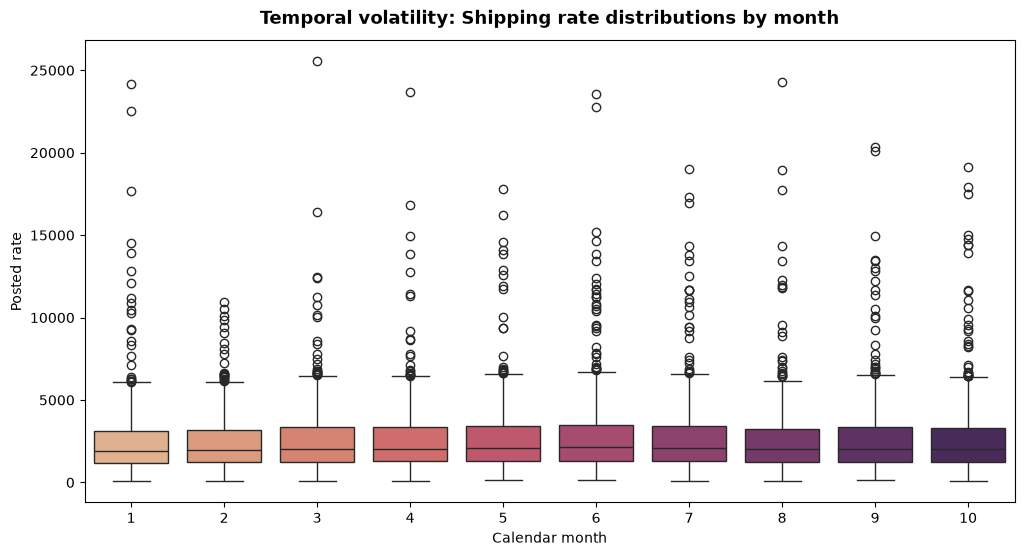

In [36]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='month',
    y='posted_rate',
    hue='month',
    palette='flare',
    legend=False
)

plt.title("Temporal volatility: Shipping rate distributions by month", fontsize=13, weight="bold", pad=12)
plt.xlabel("Calendar month")
plt.ylabel("Posted rate")
plt.show()

rate based on calendar month has pretty stable median. high rate seem to have slight wave like structure (which may indicate seasonality). month 3 and to an extent month 8 seems to go all the way to the maximum rate. month 2 seems to have the most stable median. month 3 is march and month 8 is august, indicating slight seasonality (quarterly).

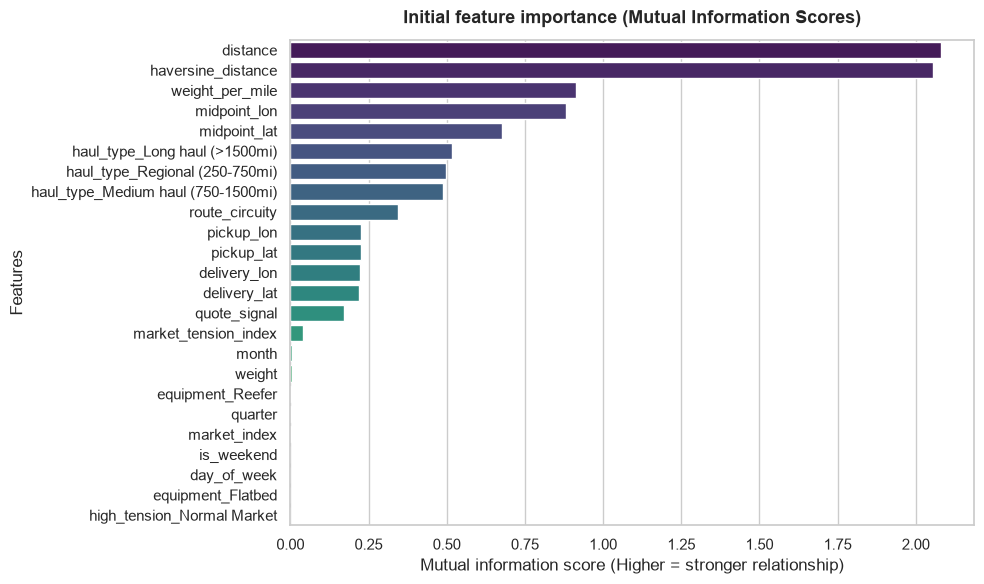

In [37]:
from sklearn.feature_selection import mutual_info_regression


drop_cols = [
    "load_id",
    "pickup",
    "delivery",
    "lane",
    "date",
    "posted_rate",
    "log_posted_rate",
    "weight_class",
]

X_numeric = df.drop(columns=drop_cols, errors="ignore")

X_numeric = pd.get_dummies(X_numeric, drop_first=True, dtype=int)
y = df["log_posted_rate"]

mi_scores = mutual_info_regression(X_numeric, y, random_state=42)

importance_df = pd.DataFrame(
    {"Feature": X_numeric.columns, "Importance": mi_scores}
).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False,
)

plt.title(
    "Initial feature importance (Mutual Information Scores)",
    fontsize=13,
    weight="bold",
    pad=12,
)
plt.xlabel("Mutual information score (Higher = stronger relationship)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

from the above plot, it is clear distance and haversine_distance are the most important features (each having over mis of 2). 

whereas, if we look at the weight_per_mile (mis of roughly close to 1) and weight (mis of near 0), it seems like weight matters when considered with how far it has to be transported.

but features such month, weight, equipment_Reefer, etc. seem to be dead weight. thus they can be dropped.

IMPORTANT: features like pickup, delivery are already inside features like lat, lon so they will be dropped.

<h2>Model prototype</h2>

In [38]:
df_ = df_.drop(columns=["pickup", "delivery", "load_id"])
df_

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
...,...,...,...,...,...,...,...,...,...,...,...
47995,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46


In [39]:
df_.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


In [40]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

df_cleaned = df_.copy()

# for getting rid of negative sign
df_cleaned['weight'] = df_cleaned['weight'].abs()

# for haversince_distance
lat1, lon1, lat2, lon2 = map(
    np.radians, 
    [df_cleaned['pickup_lat'], df_cleaned['pickup_lon'], df_cleaned['delivery_lat'], df_cleaned['delivery_lon']]
)

dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
df_cleaned['haversine_distance'] = 2 * 3956 * np.arcsin(np.sqrt(a))

df_cleaned['route_circuity'] = df_cleaned['distance'] / (df_cleaned['haversine_distance'] + 1e-5)

# log distance to get non-linearity if any
df_cleaned['log_distance'] = np.log1p(df_cleaned['distance'])

# heading angle from pickup to delivery
x = np.sin(dlon) * np.cos(lat2)
y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
df_cleaned['pickup_delivery_bearing'] = np.arctan2(x, y)

# lon and lat middle point
df_cleaned['midpoint_lat'] = (df_cleaned['pickup_lat'] + df_cleaned['delivery_lat']) / 2
df_cleaned['midpoint_lon'] = (df_cleaned['pickup_lon'] + df_cleaned['delivery_lon']) / 2

# for binning the distance based on the haul type
bins = [0, 250, 750, 1500, float('inf')]
labels = ['short_haul', 'regional', 'medium_haul', 'long_haul']
df_cleaned['haul_type'] = pd.cut(df_cleaned['distance'], bins=bins, labels=labels).astype(str)

# scaling the y (posted_rate)
df_cleaned['log_posted_rate'] = np.log1p(df_cleaned['posted_rate'])

# encoding the equipment and haul type
df_encoded = pd.get_dummies(df_cleaned, columns=['equipment', 'haul_type'], drop_first=True, dtype=int)

# optimal features list
optimal_features = [
    'distance', 'log_distance', 'haversine_distance', 'weight_per_mile', 
    'midpoint_lon', 'midpoint_lat', 'route_circuity', 'pickup_lon', 'pickup_lat', 
    'delivery_lon', 'delivery_lat', 'pickup_delivery_bearing',
    'quote_signal', 'market_tension_index', 
    'total_payload_weight', 'excess_distance',
    'equipment_Flatbed', 'equipment_Reefer', 
    'haul_type_regional', 'haul_type_medium_haul', 'haul_type_short_haul', 
    'weight', 'market_index'
]

X = df_encoded.copy()
y = df_encoded['log_posted_rate']

# binning the y for capturing the bimodal dataset stratification
y_binned = pd.qcut(y, q=6, labels=False, duplicates='drop')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y_binned)


train_weight_median = X_train['weight'].median()
train_market_median = X_train['market_index'].median()


for df_split in [X_train, X_test]:
    df_split['weight'] = df_split['weight'].fillna(train_weight_median)
    df_split['market_index'] = df_split['market_index'].fillna(train_market_median)


for df_split in [X_train, X_test]:
    df_split['weight_per_mile'] = df_split['weight'] / df_split['distance']
    df_split['market_tension_index'] = df_split['market_index'] * df_split['quote_signal']
    df_split['total_payload_weight'] = df_split['weight_per_mile'] * df_split['distance']
    df_split['excess_distance'] = df_split['distance'] * (df_split['route_circuity'] - 1)

X_train = X_train[optimal_features]
X_test = X_test[optimal_features]

X_train = X_train.drop(columns=['weight', 'market_index'])
X_test = X_test.drop(columns=['weight', 'market_index'])

print("\n")
print(X_train.info())



<class 'pandas.DataFrame'>
Index: 38400 entries, 1878 to 18860
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   distance                 38400 non-null  float64
 1   log_distance             38400 non-null  float64
 2   haversine_distance       38400 non-null  float64
 3   weight_per_mile          38400 non-null  float64
 4   midpoint_lon             38400 non-null  float64
 5   midpoint_lat             38400 non-null  float64
 6   route_circuity           38400 non-null  float64
 7   pickup_lon               38400 non-null  float64
 8   pickup_lat               38400 non-null  float64
 9   delivery_lon             38400 non-null  float64
 10  delivery_lat             38400 non-null  float64
 11  pickup_delivery_bearing  38400 non-null  float64
 12  quote_signal             38400 non-null  float64
 13  market_tension_index     38400 non-null  float64
 14  total_payload_weight     38400 no

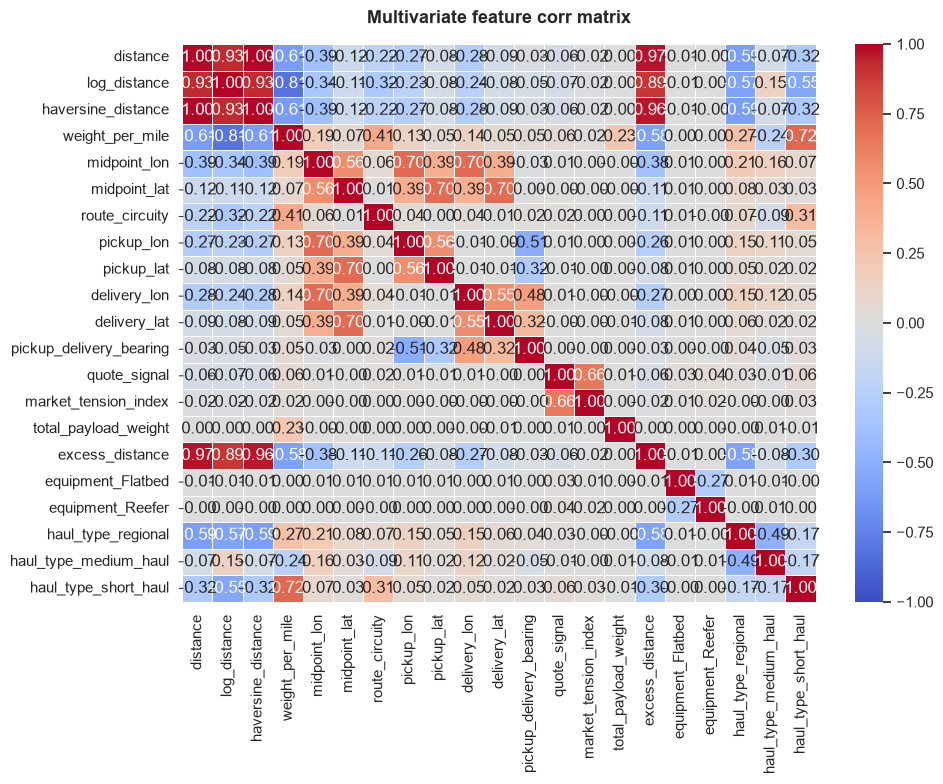

In [41]:
# features = ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 
#             'distance', 'weight', 'market_index', 'quote_signal', 'posted_rate', 'log_posted_rate']

plt.figure(figsize=(10, 8))
sns.heatmap(
    X_train.corr(), 
    annot=True, 
    cmap="coolwarm", 
    fmt=".2f", 
    linewidths=0.7, 
    vmin=-1, 
    vmax=1
)

plt.title("Multivariate feature corr matrix", fontsize=13, weight="bold", pad=15)
plt.tight_layout()
plt.show()

Looking at the above matrix, some features have low correlation while others have perfect correlation. 

Haversine_distance, log_distance, excess_distance and distance seem to be corr perfectly or pretty close to perfect corr. While pretty much all other features have pretty low correlation. 

If such correlation exists, why are those features kept. Well, because I choose to use tree-based models rather than models like Logistic Regression.

In [273]:
X_train.describe()

,distance,log_distance,haversine_distance,weight_per_mile,midpoint_lon,midpoint_lat,route_circuity,pickup_lon,pickup_lat,delivery_lon,...,pickup_delivery_bearing,quote_signal,market_tension_index,total_payload_weight,excess_distance,equipment_Flatbed,equipment_Reefer,haul_type_regional,haul_type_medium_haul,haul_type_short_haul
count,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,...,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000,38400.000000
mean,1135.774479,6.799494,965.324734,47.703405,-90.915815,35.650145,1.195002,-90.927419,35.659185,-90.904212,...,-0.197127,2.063244,2.232573,31413.866927,201.416045,0.182552,0.250885,0.318698,0.340938,0.055573
std,728.265736,0.738657,629.836664,51.175186,9.504105,3.039702,0.125706,13.493202,4.317138,13.506209,...,1.628550,0.291077,0.458599,7959.116034,117.009931,0.386304,0.433528,0.465978,0.474031,0.229098
min,70.000000,4.262680,7.260101,2.051871,-120.746885,28.461945,1.058839,-121.698490,28.357650,-121.698490,...,-3.139037,0.692280,0.619774,5000.000000,4.883630,0.000000,0.000000,0.000000,0.000000,0.000000
25%,549.700000,6.311190,456.208150,18.687393,-97.811000,33.384345,1.165643,-98.400590,31.986910,-98.400590,...,-1.695771,1.891410,1.899785,25959.750000,109.503285,0.000000,0.000000,0.000000,0.000000,0.000000
50%,954.100000,6.861816,809.169982,32.177299,-89.305305,35.633350,1.183163,-88.089150,35.294790,-87.528710,...,0.038073,2.055965,2.181678,31495.500000,171.077674,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1644.600000,7.405860,1409.673045,56.281958,-83.998350,37.677715,1.205789,-83.285060,39.411040,-83.285060,...,1.195985,2.223120,2.526888,37009.250000,275.164447,0.000000,1.000000,1.000000,1.000000,0.000000
max,3439.800000,8.143459,2871.620092,678.571429,-69.500000,44.136355,9.641725,-69.500000,44.302960,-69.500000,...,3.141593,3.610350,4.873034,47500.000000,708.616907,1.000000,1.000000,1.000000,1.000000,1.000000


In [274]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model_dic = {
    'LightGBM': lgb.LGBMRegressor(random_state=42, n_jobs=-1, force_col_wise=True, verbose=-1),
    # using squarederror as loss function as it is standard objective
    'XGBoost': xgb.XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=-1),
    'RandomForest': RandomForestRegressor(random_state=42, n_jobs=-1)
}

model_params = {
    'LightGBM': {
        'n_estimators': [500, 800, 1000], # number of trees built so, keeping it low to high (pushed higher since 500 won)
        'learning_rate': [0.01, 0.03, 0.05], # focused around 0.03
        'max_depth': [3, 4, 5], # checking deep tree or small one (centered around 4)
        'num_leaves': [15, 31, 45], # width of the model 
        'subsample': [0.7, 0.8, 0.9], # for reducing overfitting, using low to high
        'colsample_bytree': [0.8, 0.9, 1.0], # fraction of sample looked for best spliting
        'reg_alpha': [0.0, 0.01], # for sparsity
        'reg_lambda': [0.1, 0.5, 1.0], # for smoothing the weight (shifted slightly higher since 0.5 won)
        'min_child_weight': [3, 5, 7] # amount of data required to split
    },
    'XGBoost': {
        'n_estimators': [1000, 1200, 1500], # number of trees built so, keeping it low to high (pushed higher since 1000 hit the ceiling)
        'learning_rate': [0.01, 0.02, 0.03], # shifted lower to pair with 1000+ trees
        'max_depth': [2, 3, 4], # checking deep tree or small one (centered around 3)
        'subsample': [0.7, 0.8, 0.9], # for reducing overfitting, using low to high
        'colsample_bytree': [0.8, 0.9, 1.0], # fraction of sample looked for best spliting
        'min_child_weight': [10, 15, 20], # amount of data required to split, keeping it low to high (pushed higher since 10 hit the ceiling)
        'reg_alpha': [0.0, 0.01, 0.1], # for sparsity
        'reg_lambda': [50.0, 75.0, 100.0] # for smoothing the weight (pushed higher since 50.0 hit the ceiling)
    },
    'RandomForest': {
        'n_estimators': [300, 400, 500], # number of trees built so, keeping it low to high (focused around 400)
        'max_depth': [15, 20, 25], # checking deep tree or small one
        'min_samples_split': [15, 20, 25], # checking for high or low sample limit to split the node (shifted higher since 15 won)
        'min_samples_leaf': [10, 12, 15], # amount of data required to split, keeping it low to high (centered around 12)
        'max_features': [0.4, 0.5, 0.6] # maximum number to be looked when checking for best split (shifted lower since 0.6 won)
    }
}

In [275]:
best_estimators = {}
model_performance_results = {}
y_test_usd = np.expm1(y_test.values)

for m_name, init_model in model_dic.items():
    
    search = RandomizedSearchCV(
        estimator=init_model,
        param_distributions=model_params[m_name],
        n_iter=10, # 10 as it seemed like the good iteration
        cv=3, # default for now
        scoring='r2',
        refit=True,
        random_state=42,
        n_jobs=-1,
    )
    n_candidates = search.n_iter
    n_folds = search.cv
    total_fits = n_candidates * n_folds
    
    print(f"Fitting {m_name} model {total_fits} times ({n_candidates} candidates × {n_folds} folds)...")
    
    search.fit(X_train, y_train)
    
    best_model = search.best_estimator_
    
    best_estimators[m_name] = best_model
    
    preds_log = best_model.predict(X_test)
    preds_usd = np.clip(np.expm1(preds_log), a_min=0.0, a_max=None)
    
    # calculating performance indices
    test_r2 = r2_score(y_test_usd, preds_usd)
    test_rmse = np.sqrt(mean_squared_error(y_test_usd, preds_usd))
    test_mae = mean_absolute_error(y_test_usd, preds_usd)
    
    print(f"-> Selected Parameters: {search.best_params_}")
    print(f"-> Test Scores: R² = {test_r2:.4f} | RMSE = ${test_rmse:.2f} | MAE = ${test_mae:.2f}\n")
    
    model_performance_results[m_name] = {
        'predictions_usd': preds_usd,
        'r2': test_r2,
        'rmse': test_rmse,
        'mae': test_mae
    }

Fitting LightGBM model 30 times (10 candidates × 3 folds)...
-> Selected Parameters: {'subsample': 0.8, 'reg_lambda': 0.1, 'reg_alpha': 0.01, 'num_leaves': 15, 'n_estimators': 800, 'min_child_weight': 7, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.9}
-> Test Scores: R² = 0.8514 | RMSE = $570.30 | MAE = $103.10

Fitting XGBoost model 30 times (10 candidates × 3 folds)...
-> Selected Parameters: {'subsample': 0.9, 'reg_lambda': 100.0, 'reg_alpha': 0.01, 'n_estimators': 1200, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 1.0}
-> Test Scores: R² = 0.8516 | RMSE = $569.89 | MAE = $101.94

Fitting RandomForest model 30 times (10 candidates × 3 folds)...
-> Selected Parameters: {'n_estimators': 400, 'min_samples_split': 25, 'min_samples_leaf': 12, 'max_features': 0.6, 'max_depth': 25}
-> Test Scores: R² = 0.8518 | RMSE = $569.60 | MAE = $101.38



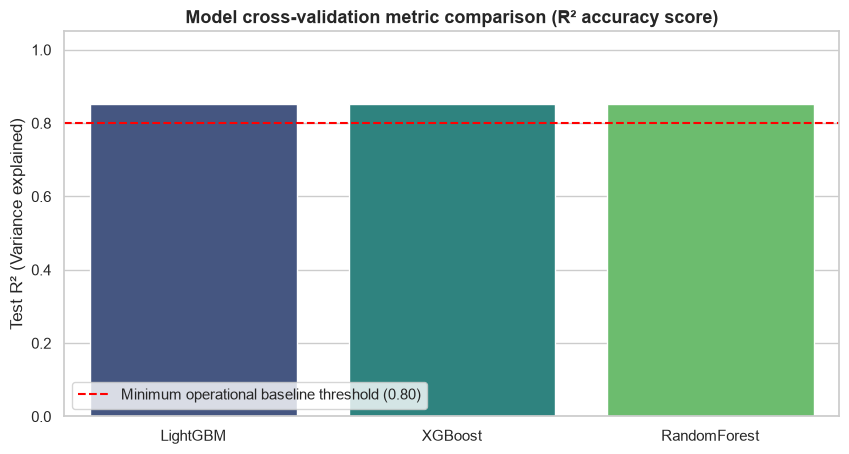

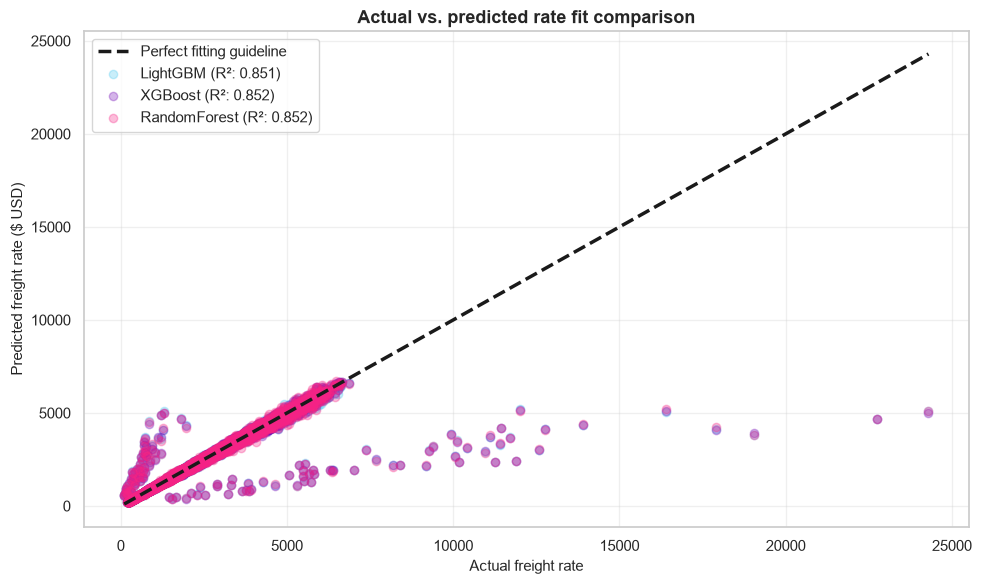

In [276]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))
models_list = list(model_performance_results.keys())
r2_scores_list = [res['r2'] for res in model_performance_results.values()]

sns.barplot(x=models_list, y=r2_scores_list, hue=models_list, palette="viridis", legend=False)
plt.axhline(0.80, color='red', linestyle='--', label='Minimum operational baseline threshold (0.80)')
plt.ylabel("Test R² (Variance explained)")
plt.title("Model cross-validation metric comparison (R² accuracy score)", fontsize=13, weight='bold')
plt.ylim(0, 1.05)
plt.legend(loc='lower left')
plt.show()

plt.figure(figsize=(10, 6))
colors_map = {'LightGBM': '#4cc9f0', 'XGBoost': '#7209b7', 'RandomForest': '#f72585'}

ideal_line = [y_test_usd.min(), y_test_usd.max()]
plt.plot(ideal_line, ideal_line, "k--", linewidth=2.5, label="Perfect fitting guideline")

for m_name, res in model_performance_results.items():
    plt.scatter(
        y_test_usd, 
        res['predictions_usd'], 
        alpha=0.3, 
        color=colors_map[m_name], 
        label=f"{m_name} (R²: {res['r2']:.3f})"
    )

plt.xlabel("Actual freight rate", fontsize=11)
plt.ylabel("Predicted freight rate ($ USD)", fontsize=11)
plt.title("Actual vs. predicted rate fit comparison", fontsize=13, weight='bold')
plt.legend(loc='upper left')
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()


TRYING ENSEMBLE TO SEE IF IT CAN BREAK THE R^2

In [278]:
best_estimators = {}
model_performance_results = {}

y_test_log = y_test.values
y_test_usd = np.expm1(y_test_log)

for m_name, init_model in model_dic.items():
    
    search = RandomizedSearchCV(
        estimator=init_model,
        param_distributions=model_params[m_name],
        n_iter=10, # 10 as it seemed like the good iteration
        cv=3, # default for now
        scoring='r2',
        refit=True,
        random_state=42,
        n_jobs=-1,
    )
    n_candidates = search.n_iter
    n_folds = search.cv
    total_fits = n_candidates * n_folds
    
    print(f"Fitting {m_name} model {total_fits} times ({n_candidates} candidates × {n_folds} folds)...")
    
    search.fit(X_train, y_train)
    
    best_model = search.best_estimator_
    best_estimators[m_name] = best_model
    
    preds_log = best_model.predict(X_test)
    preds_usd = np.clip(np.expm1(preds_log), a_min=0.0, a_max=None)
    
    # Calculating performance indices (R² on log scale matching training loss, RMSE/MAE in USD)
    test_r2 = r2_score(y_test_log, preds_log)
    test_rmse = np.sqrt(mean_squared_error(y_test_usd, preds_usd))
    test_mae = mean_absolute_error(y_test_usd, preds_usd)
    
    print(f"-> Selected Parameters: {search.best_params_}")
    print(f"-> Test Scores: R² = {test_r2:.4f} | RMSE = ${test_rmse:.2f} | MAE = ${test_mae:.2f}\n")
    
    model_performance_results[m_name] = {
        'predictions_log': preds_log,
        'predictions_usd': preds_usd,
        'r2': test_r2,
        'rmse': test_rmse,
        'mae': test_mae
    }

print("EVALUATING MODEL ENSEMBLES")

lgb_preds = model_performance_results['LightGBM']['predictions_log']
xgb_preds = model_performance_results['XGBoost']['predictions_log']
rf_preds = model_performance_results['RandomForest']['predictions_log']

ensemble_preds_log = (lgb_preds + xgb_preds + rf_preds) / 3
ensemble_preds_usd = np.clip(np.expm1(ensemble_preds_log), a_min=0.0, a_max=None)

ens_r2 = r2_score(y_test_log, ensemble_preds_log)
ens_rmse = np.sqrt(mean_squared_error(y_test_usd, ensemble_preds_usd))
ens_mae = mean_absolute_error(y_test_usd, ensemble_preds_usd)

print(f"-> Simple average ensemble test scores: R² = {ens_r2:.4f} | RMSE = ${ens_rmse:.2f} | MAE = ${ens_mae:.2f}")

weighted_preds_log = (0.2 * lgb_preds) + (0.4 * xgb_preds) + (0.4 * rf_preds)
weighted_preds_usd = np.clip(np.expm1(weighted_preds_log), a_min=0.0, a_max=None)

w_ens_r2 = r2_score(y_test_log, weighted_preds_log)
w_ens_rmse = np.sqrt(mean_squared_error(y_test_usd, weighted_preds_usd))
w_ens_mae = mean_absolute_error(y_test_usd, weighted_preds_usd)

print(f"-> Weighted Ensemble Test Scores: R² = {w_ens_r2:.4f} | RMSE = ${w_ens_rmse:.2f} | MAE = ${w_ens_mae:.2f}")

Fitting LightGBM model 30 times (10 candidates × 3 folds)...
-> Selected Parameters: {'subsample': 0.8, 'reg_lambda': 0.1, 'reg_alpha': 0.01, 'num_leaves': 15, 'n_estimators': 800, 'min_child_weight': 7, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.9}
-> Test Scores: R² = 0.9498 | RMSE = $570.30 | MAE = $103.10

Fitting XGBoost model 30 times (10 candidates × 3 folds)...
-> Selected Parameters: {'subsample': 0.9, 'reg_lambda': 100.0, 'reg_alpha': 0.01, 'n_estimators': 1200, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 1.0}
-> Test Scores: R² = 0.9499 | RMSE = $569.89 | MAE = $101.94

Fitting RandomForest model 30 times (10 candidates × 3 folds)...
-> Selected Parameters: {'n_estimators': 400, 'min_samples_split': 25, 'min_samples_leaf': 12, 'max_features': 0.6, 'max_depth': 25}
-> Test Scores: R² = 0.9497 | RMSE = $569.60 | MAE = $101.38

EVALUATING MODEL ENSEMBLES
-> Simple average ensemble test scores: R² = 0.9502 | RMSE = $569.08

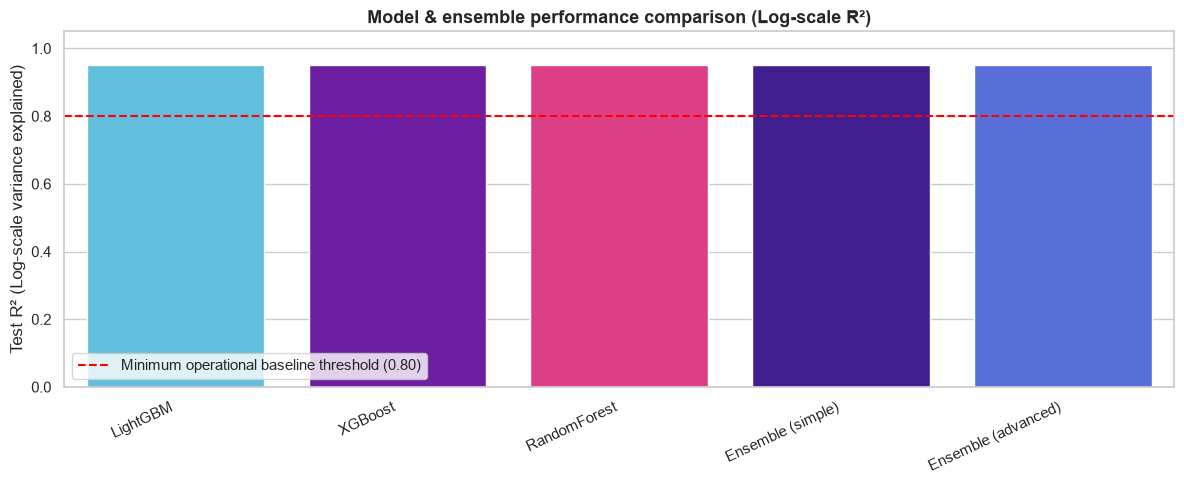

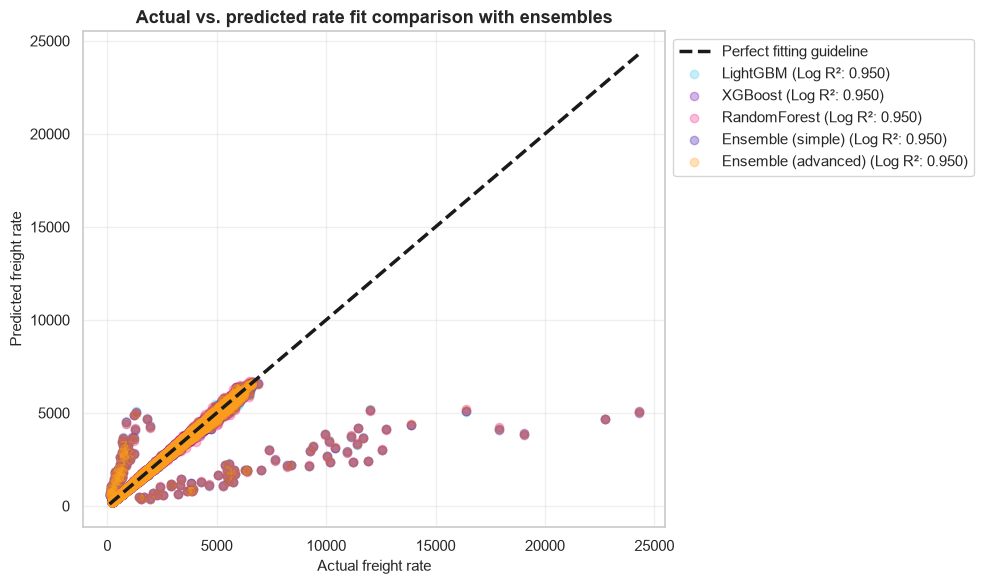

In [279]:
lgb_preds_log = model_performance_results['LightGBM']['predictions_log']
xgb_preds_log = model_performance_results['XGBoost']['predictions_log']
rf_preds_log = model_performance_results['RandomForest']['predictions_log']

# simple ensemble
ensemble_preds_log = (lgb_preds_log + xgb_preds_log + rf_preds_log) / 3
ensemble_preds_usd = np.clip(np.expm1(ensemble_preds_log), a_min=0.0, a_max=None)
ensemble_r2 = r2_score(y_test_log, ensemble_preds_log)

# weighted ensemble
weighted_preds_log = (0.2 * lgb_preds_log) + (0.4 * xgb_preds_log) + (0.4 * rf_preds_log)
weighted_preds_usd = np.clip(np.expm1(weighted_preds_log), a_min=0.0, a_max=None)
weighted_r2 = r2_score(y_test_log, weighted_preds_log)

# add them to a copy of results
extended_results = model_performance_results.copy()
extended_results['Ensemble (simple)'] = {
    'predictions_log': ensemble_preds_log,
    'predictions_usd': ensemble_preds_usd,
    'r2': ensemble_r2
}

extended_results['Ensemble (advanced)'] = {
    'predictions_log': weighted_preds_log,
    'predictions_usd': weighted_preds_usd,
    'r2': weighted_r2
}

sns.set_theme(style="whitegrid")


plt.figure(figsize=(12, 5))
models_list = list(extended_results.keys())
r2_scores_list = [res['r2'] for res in extended_results.values()]

palette = ["#4cc9f0", "#7209b7", "#f72585", "#3a0ca3", "#4361ee"]
sns.barplot(x=models_list, y=r2_scores_list, hue=models_list, palette=palette, legend=False)
plt.axhline(0.80, color='red', linestyle='--', label='Minimum operational baseline threshold (0.80)')
plt.ylabel("Test R² (Log-scale variance explained)")
plt.title("Model & ensemble performance comparison (Log-scale R²)", fontsize=13, weight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
colors_map = {
    'LightGBM': '#4cc9f0', 
    'XGBoost': '#7209b7', 
    'RandomForest': '#f72585',
    'Ensemble (simple)': '#3a0ca3',
    'Ensemble (advanced)': '#ff9f1c'
}

ideal_line = [y_test_usd.min(), y_test_usd.max()]
plt.plot(ideal_line, ideal_line, "k--", linewidth=2.5, label="Perfect fitting guideline")

for m_name, res in extended_results.items():
    plt.scatter(
        y_test_usd, 
        res['predictions_usd'], 
        alpha=0.3, 
        color=colors_map[m_name], 
        label=f"{m_name} (Log R²: {res['r2']:.3f})"
    )

plt.xlabel("Actual freight rate", fontsize=11)
plt.ylabel("Predicted freight rate", fontsize=11)
plt.title("Actual vs. predicted rate fit comparison with ensembles", fontsize=13, weight='bold')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

<h2>in conclusion</h2>

it seems like the models R^2 was low because of using converted y rather than y_log itself (how do i know this? looking at RMSE they are pretty much same between those two only R^2 differs, indicating the model was performing good rather i was calculating the metrics wrong way). the latest one takes care of that.

at the same time, i have tried ensemble model for increasing the R^2.

looking at the metrics of the models: all of them perform the same with ensemble both simple and advance having the best metrics.

since, i don't know if this model is for online or batch prediction. well, i guess that is what validation.csv is for basically for batch prediction.

for online production, lightgbm would make more sense as it is lightweight and consume less memory and of course, performs similar to other models including ensembles.

so, i will assume this is for batch prediction and thus will use ensemble (adv) in production.